In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

df = pd.read_csv("../data/processed/lfs_cleaned.csv")

X = df.drop(columns=["labor_status"])
y = df["labor_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 53042
Testing samples: 13261


In [2]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_cols = ["age", "household_size"]
cat_cols = ["gender", "marital_status", "urban_rural", "district", "education_level"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("X_train shape:", X_train_prep.shape)
print("X_test shape:", X_test_prep.shape)

X_train shape: (53042, 43)
X_test shape: (13261, 43)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_prep, y_train)

y_pred_lr = model_lr.predict(X_test_prep)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Macro F1:", f1_score(y_test, y_pred_lr, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.5976924817132946
Macro F1: 0.4123673545838431

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.61      0.72      0.66      6719
         Unemployed       0.00      0.00      0.00      1170
out of labour force       0.58      0.57      0.57      5372

           accuracy                           0.60     13261
          macro avg       0.40      0.43      0.41     13261
       weighted avg       0.54      0.60      0.57     13261



c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

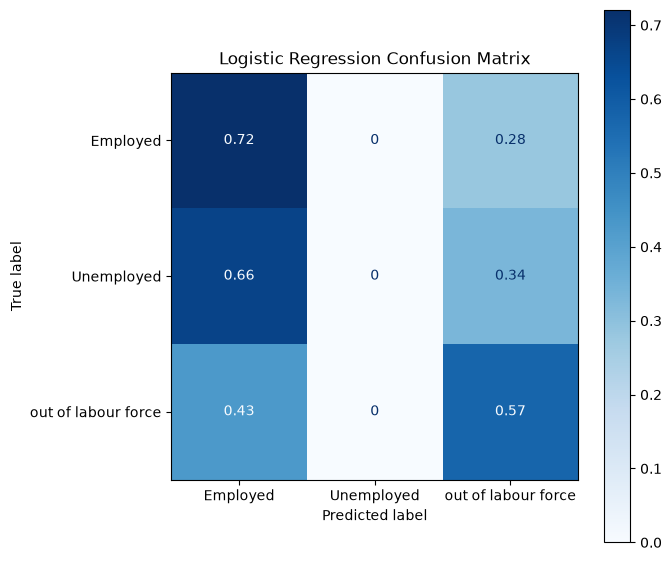

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_lr, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_logistic_regression.png", dpi=300)
plt.show()

Accuracy: 0.5152703416031973
Macro F1: 0.4472129367195717

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.68      0.46      0.55      6719
         Unemployed       0.14      0.34      0.20      1170
out of labour force       0.57      0.62      0.59      5372

           accuracy                           0.52     13261
          macro avg       0.46      0.47      0.45     13261
       weighted avg       0.59      0.52      0.54     13261



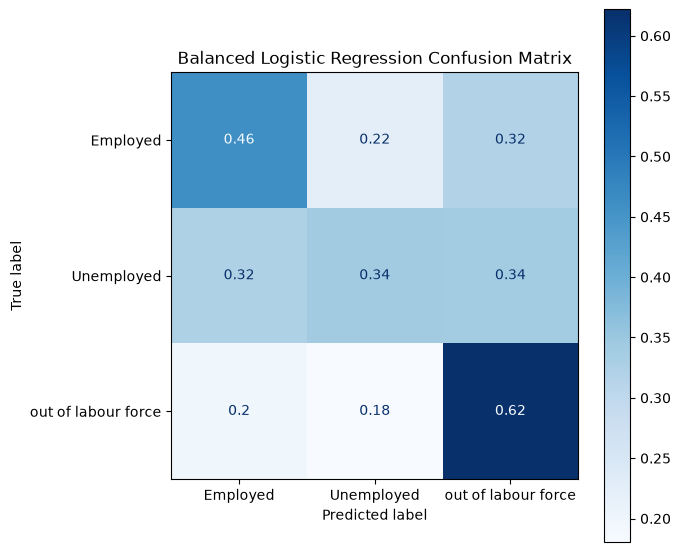

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

model_lr_balanced = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model_lr_balanced.fit(X_train_prep, y_train)

y_pred_lr_bal = model_lr_balanced.predict(X_test_prep)

print("Accuracy:", accuracy_score(y_test, y_pred_lr_bal))
print("Macro F1:", f1_score(y_test, y_pred_lr_bal, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr_bal))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_lr_bal, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Balanced Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_logistic_regression_balanced.png", dpi=300)
plt.show()

In [6]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1)
model_rf.fit(X_train_prep, y_train)

y_pred_rf = model_rf.predict(X_test_prep)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Macro F1:", f1_score(y_test, y_pred_rf, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Accuracy: 0.6255938466179021
Macro F1: 0.514073827949299

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.71      0.66      0.69      6719
         Unemployed       0.16      0.23      0.19      1170
out of labour force       0.67      0.67      0.67      5372

           accuracy                           0.63     13261
          macro avg       0.51      0.52      0.51     13261
       weighted avg       0.65      0.63      0.64     13261



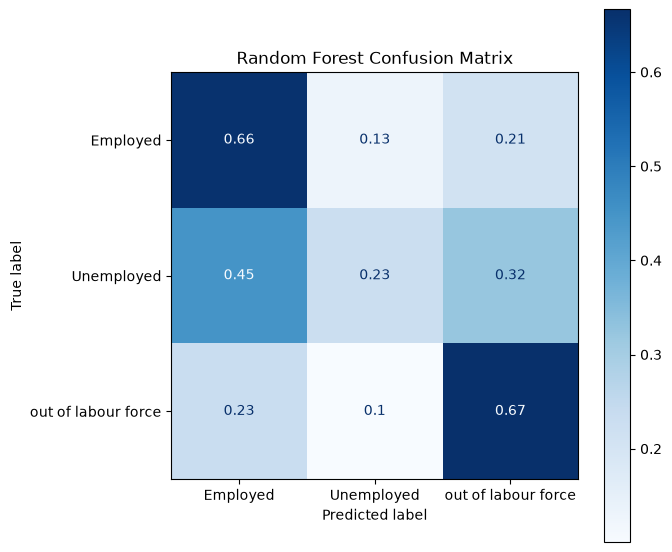

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_rf, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_random_forest.png", dpi=300)
plt.show()

In [8]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

sample_weights = compute_sample_weight("balanced", y_train_enc)

model_xgb = XGBClassifier(n_estimators=100, random_state=42, eval_metric="mlogloss")
model_xgb.fit(X_train_prep, y_train_enc, sample_weight=sample_weights)

y_pred_xgb_enc = model_xgb.predict(X_test_prep)
y_pred_xgb = le.inverse_transform(y_pred_xgb_enc)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Macro F1:", f1_score(y_test, y_pred_xgb, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

Accuracy: 0.5676796621672574
Macro F1: 0.5034348595762186

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.73      0.56      0.63      6719
         Unemployed       0.15      0.45      0.22      1170
out of labour force       0.71      0.61      0.66      5372

           accuracy                           0.57     13261
          macro avg       0.53      0.54      0.50     13261
       weighted avg       0.67      0.57      0.61     13261



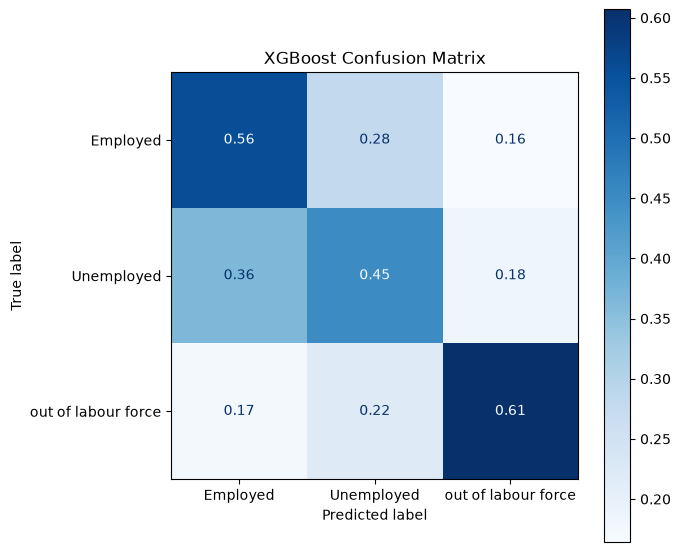

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_xgboost.png", dpi=300)
plt.show()